In [1]:
# Import required libraries

import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

%matplotlib inline

In [2]:
# Check files available in the current folder

import os

print(os.listdir())

['.ipynb_checkpoints', 'car data.csv', 'OASIS INFOBYTE — Task List.pdf', 'readme', 'SMSSpamCollection', 'spam.csv', 'Task_1_Iris_Flower_Classification.ipynb', 'Task_2_Unemployment_Analysis.ipynb', 'Task_3_Car_Price_Prediction.ipynb', 'Task_4_Email_Spam_Detection.ipynb', 'Unemployment in India.csv']


In [3]:
# Load the SMS Spam Collection dataset
# This file is tab-separated and usually has no header

df = pd.read_csv(
    "SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

# Display first 5 rows
display(df.head())

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
# Check dataset size and column information

print("Dataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Counts:")
print(df["label"].value_counts())

Dataset Shape: (5572, 2)

Column Names: ['label', 'message']

Missing Values:
label      0
message    0
dtype: int64

Class Counts:
label
ham     4825
spam     747
Name: count, dtype: int64


In [5]:
# Count each message category

class_counts = df["label"].value_counts()

# Calculate percentages
class_percentages = (
    df["label"].value_counts(normalize=True) * 100
)

distribution_df = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

display(distribution_df)

,Count,Percentage
label,,
ham,4825,86.59
spam,747,13.41


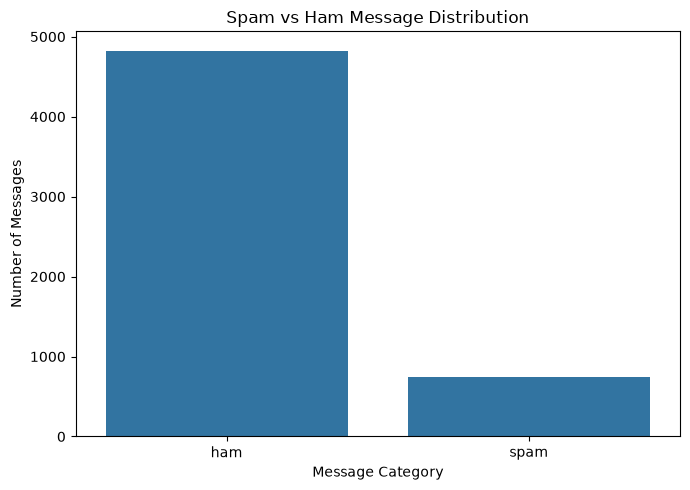

In [6]:
# Visualize spam and ham counts

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="label"
)

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()

Observation:
The class distribution shows the number and percentage of spam and ham messages. If ham messages significantly outnumber spam messages, the dataset is imbalanced. Therefore, accuracy alone may not be sufficient to evaluate the classifier.

In [7]:
# Define common English stopwords
# No extra downloads required

stop_words = {
    "i", "me", "my", "myself", "we", "our", "ours",
    "you", "your", "yours", "he", "him", "his",
    "she", "her", "it", "its", "they", "them", "their",
    "what", "which", "who", "this", "that", "these",
    "those", "am", "is", "are", "was", "were", "be",
    "been", "being", "have", "has", "had", "do", "does",
    "did", "a", "an", "the", "and", "but", "if", "or",
    "because", "as", "until", "while", "of", "at", "by",
    "for", "with", "about", "against", "between", "into",
    "through", "during", "before", "after", "above", "below",
    "to", "from", "up", "down", "in", "out", "on", "off",
    "over", "under", "again", "further", "then", "once"
}

In [8]:
# Function to clean text messages

def clean_text(text):
    # Convert text to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Remove numbers
    text = re.sub(r"\d+", " ", text)

    # Split into individual words
    words = text.split()

    # Remove stopwords
    words = [word for word in words if word not in stop_words]

    # Join cleaned words
    return " ".join(words)


# Apply text cleaning
df["clean_message"] = df["message"].apply(clean_text)

# Compare original and cleaned messages
display(df[["message", "clean_message"]].head(10))

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available only bugis n g...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around here though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling weeks now no word ba...
6,Even my brother is not like to speak with me. ...,even brother not like speak treat like aids pa...
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile months more u r entitled update latest ...


In [9]:
print("Missing cleaned messages:", df["clean_message"].isnull().sum())
print("\nSample cleaned spam messages:")

display(
    df.loc[df["label"] == "spam", ["message", "clean_message"]].head(5)
)

Missing cleaned messages: 0

Sample cleaned spam messages:


,message,clean_message
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling weeks now no word ba...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile months more u r entitled update latest ...
11,"SIX chances to win CASH! From 100 to 20,000 po...",six chances win cash pounds txt csh send cost ...


TF-IDF (Term Frequency–Inverse Document Frequency):

Term Frequency measures how frequently a word appears in a message.
Inverse Document Frequency reduces the weight of words that appear
in many messages.

TF-IDF converts text into numerical features that machine learning
models can use for spam classification.

In [10]:
# Remove rows with missing or empty cleaned messages
df = df.dropna(subset=["clean_message", "label"]).copy()
df = df[df["clean_message"].str.strip() != ""]
df = df[df["label"].isin(["ham", "spam"])]

# Separate features and target labels
X = df["clean_message"]
y = df["label"]

print("Total messages:", len(df))
print("Ham messages:", (y == "ham").sum())
print("Spam messages:", (y == "spam").sum())

Total messages: 5569
Ham messages: 4822
Spam messages: 747


In [11]:
# Split the data while preserving the ham/spam ratio
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4455
Testing messages: 1114


In [12]:
# Learn TF-IDF features only from training messages
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)
print("Number of vocabulary terms:", len(tfidf.vocabulary_))

Training feature shape: (4455, 5000)
Testing feature shape: (1114, 5000)
Number of vocabulary terms: 5000


In [13]:
# Model 1: Multinomial Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# Model 2: Logistic Regression
lr_model = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_model.fit(X_train_tfidf, y_train)

print("Both models trained successfully!")

Both models trained successfully!



Model: Multinomial Naive Bayes
Accuracy : 0.9713
Precision: 1.0000
Recall   : 0.7852
F1-Score : 0.8797

Classification Report:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       965
        spam       1.00      0.79      0.88       149

    accuracy                           0.97      1114
   macro avg       0.98      0.89      0.93      1114
weighted avg       0.97      0.97      0.97      1114



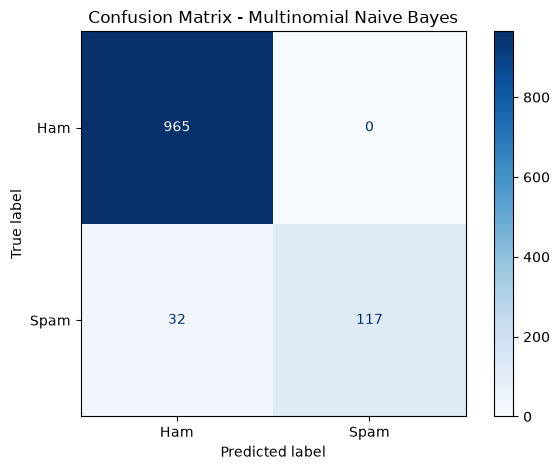


Model: Logistic Regression
Accuracy : 0.9785
Precision: 0.9195
Recall   : 0.9195
F1-Score : 0.9195

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       965
        spam       0.92      0.92      0.92       149

    accuracy                           0.98      1114
   macro avg       0.95      0.95      0.95      1114
weighted avg       0.98      0.98      0.98      1114



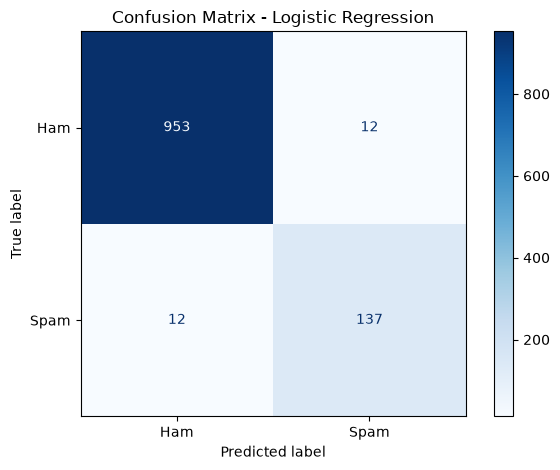

In [14]:
# Function to evaluate a model
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, pos_label="spam", zero_division=0)
    recall = recall_score(y_test, y_pred, pos_label="spam", zero_division=0)
    f1 = f1_score(y_test, y_pred, pos_label="spam", zero_division=0)

    print(f"\n{'=' * 45}")
    print(f"Model: {model_name}")
    print(f"{'=' * 45}")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        labels=["ham", "spam"],
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Ham", "Spam"]
    )
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }


# Evaluate both models
nb_results = evaluate_model(
    nb_model, X_test_tfidf, y_test, "Multinomial Naive Bayes"
)

lr_results = evaluate_model(
    lr_model, X_test_tfidf, y_test, "Logistic Regression"
)

In [15]:
results_df = pd.DataFrame([nb_results, lr_results])

display(
    results_df.sort_values(
        by="F1-Score", ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score
1,Logistic Regression,0.9785,0.9195,0.9195,0.9195
0,Multinomial Naive Bayes,0.9713,1.0000,0.7852,0.8797


### Model Evaluation and Conclusion

Two machine learning models, Multinomial Naive Bayes and Logistic Regression, were trained using TF-IDF features to classify SMS messages as spam or ham.

The models were evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

Recall is important in spam detection because low spam recall means that some spam messages may be incorrectly classified as legitimate messages and reach the user's inbox. Precision is also important because low precision can cause legitimate messages to be marked as spam.

The final model should be selected based on its evaluation results and the balance between precision and recall.


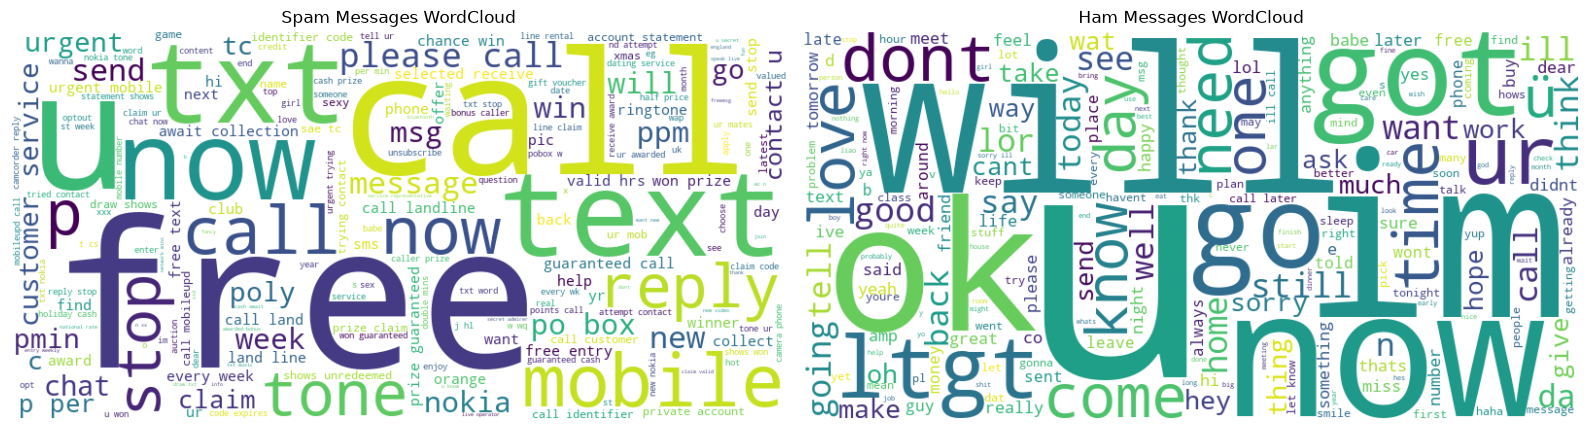

In [16]:
from wordcloud import WordCloud

# Combine cleaned messages by category
spam_text = " ".join(
    df.loc[df["label"] == "spam", "clean_message"]
)

ham_text = " ".join(
    df.loc[df["label"] == "ham", "clean_message"]
)

# Display both word clouds
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

spam_cloud = WordCloud(
    width=800, height=400,
    background_color="white"
).generate(spam_text)

ham_cloud = WordCloud(
    width=800, height=400,
    background_color="white"
).generate(ham_text)

axes[0].imshow(spam_cloud, interpolation="bilinear")
axes[0].set_title("Spam Messages WordCloud")
axes[0].axis("off")

axes[1].imshow(ham_cloud, interpolation="bilinear")
axes[1].set_title("Ham Messages WordCloud")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Test messages
sample_messages = [
    "Congratulations! You have won a free prize. Call now to claim.",
    "Hi, are we meeting for lunch today?",
    "URGENT! You have won a cash reward. Claim your free gift now."
]

# Clean and transform messages using the trained TF-IDF vectorizer
cleaned_samples = [clean_text(message) for message in sample_messages]
sample_features = tfidf.transform(cleaned_samples)

# Predict using both models
nb_predictions = nb_model.predict(sample_features)
lr_predictions = lr_model.predict(sample_features)

prediction_results = pd.DataFrame({
    "Message": sample_messages,
    "Naive Bayes Prediction": nb_predictions,
    "Logistic Regression Prediction": lr_predictions
})

display(prediction_results)

,Message,Naive Bayes Prediction,Logistic Regression Prediction
0,Congratulations! You have won a free prize. Ca...,spam,spam
1,"Hi, are we meeting for lunch today?",ham,ham
2,URGENT! You have won a cash reward. Claim your...,spam,spam
